In [1]:
# Program 6: K-Means Clustering on Sales Data
# Dataset: https://www.kaggle.com/datasets/kyanyoga/sample-sales-data (sales_data_sample.csv)

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

%matplotlib inline

In [2]:
# Step 1: Load Dataset
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,Motorcycles,95,S10_1678,Corporate Gift Ideas Co.,6505551386,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
# Step 2: Select Features and Clean Data
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
df_clean = df[features].dropna().copy()
print(f"Selected Features: {features}")
df_clean.describe().round(2)

Selected Features: ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
count,2823.00,2823.00,2823.00,2823.00
mean,35.09,83.66,3553.89,100.72
std,9.74,20.17,1841.87,40.19
min,6.00,26.88,482.13,33.00
25%,27.00,68.86,2203.43,68.00
50%,35.00,95.70,3184.80,99.00
75%,43.00,100.00,4508.00,124.00
max,97.00,100.00,14082.80,214.00


In [4]:
# Step 3: Feature Scaling using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean)
print(f"Scaled matrix shape: {X_scaled.shape}")

Scaled matrix shape: (2823, 4)


In [5]:
# Step 4: Elbow Method - Compute WCSS for K = 1 to 10
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

elbow_table = pd.DataFrame({
    'Number of Clusters (K)': list(k_range),
    'WCSS (Inertia)': [round(val, 2) for val in wcss]
})
elbow_table

,Number of Clusters (K),WCSS (Inertia)
0,1,11292.00
1,2,6741.69
2,3,4766.01
3,4,3934.89
4,5,3348.27
5,6,2858.82
6,7,2548.54
7,8,2350.66
8,9,2169.97
9,10,2019.75


The elbow bend is clearly observed at K = 3.


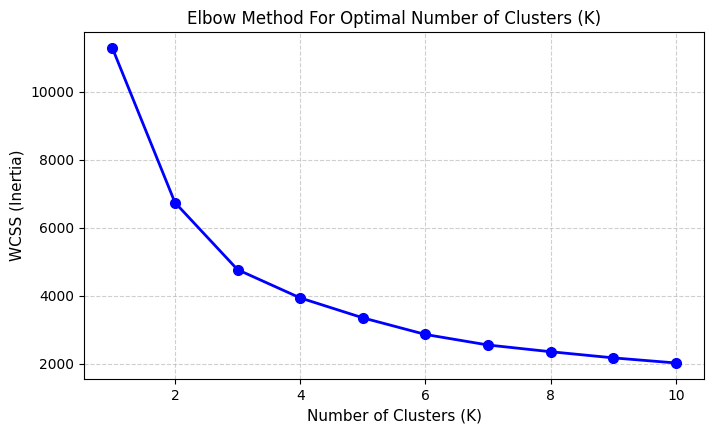

In [6]:
# Step 5: Plot Elbow Curve
plt.figure(figsize=(8, 4.5))
plt.plot(k_range, wcss, 'bo-', linewidth=2, markersize=7)
plt.title('Elbow Method For Optimal Number of Clusters (K)', fontsize=12)
plt.xlabel('Number of Clusters (K)', fontsize=11)
plt.ylabel('WCSS (Inertia)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()
print("The elbow bend is clearly observed at K = 3.")

In [7]:
# Step 6: Train K-Means with Optimal K = 3
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_clean['Cluster'] = kmeans_final.fit_predict(X_scaled)

print("Customer Counts per Cluster:")
df_clean['Cluster'].value_counts().sort_index()

Customer Counts per Cluster:


,count
Cluster,
0,975
1,852
2,996


In [8]:
# Step 7: Analyze Cluster Centroids
centroids = scaler.inverse_transform(kmeans_final.cluster_centers_)
centroids_df = pd.DataFrame(
    centroids,
    columns=features,
    index=[f"Cluster {i}" for i in range(optimal_k)]
)
print("Cluster Centroid Profiles (Original Scale):")
centroids_df.round(2)

Cluster Centroid Profiles (Original Scale):


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
Cluster 0,35.21,59.55,2101.08,64.15
Cluster 1,43.73,97.49,5722.35,127.95
Cluster 2,27.61,95.43,3123.73,113.23


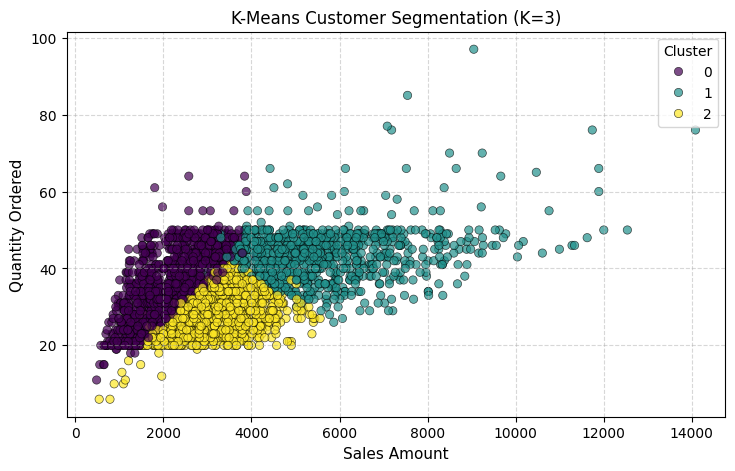

In [9]:
# Step 8: Visualize Customer Segments
plt.figure(figsize=(8.5, 5))
sns.scatterplot(
    data=df_clean,
    x='SALES',
    y='QUANTITYORDERED',
    hue='Cluster',
    palette='viridis',
    alpha=0.7,
    edgecolor='k'
)
plt.title(f'K-Means Customer Segmentation (K={optimal_k})', fontsize=12)
plt.xlabel('Sales Amount', fontsize=11)
plt.ylabel('Quantity Ordered', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:
# Step 9: Model Evaluation Metrics
sil_score = silhouette_score(X_scaled, df_clean['Cluster'])
print("=" * 45)
print(f"Optimal Number of Clusters (K) : {optimal_k}")
print(f"Final WCSS (Inertia)          : {kmeans_final.inertia_:.2f}")
print(f"Silhouette Score              : {sil_score:.4f}")
print("=" * 45)

Optimal Number of Clusters (K) : 3
Final WCSS (Inertia)          : 4766.01
Silhouette Score              : 0.3509
